Total Points: 750 | Train Steps: 525 | Test Steps: 225

--- Training on Train Set ---
Epoch 300/1200 | Loss: 4.781753e-07 | delta: 0.218, alpha: -1.000, beta: 0.999
Epoch 600/1200 | Loss: 4.781753e-07 | delta: 0.218, alpha: -1.000, beta: 0.999
Epoch 900/1200 | Loss: 4.781751e-07 | delta: 0.218, alpha: -1.000, beta: 0.999
Epoch 1200/1200 | Loss: 4.781752e-07 | delta: 0.218, alpha: -1.000, beta: 0.999

--- Running Full Rollout Inference ---

[Train Results] R² Score: 0.9959 | RMSE: 0.01813
[Test Results]  R² Score: 0.9671 | RMSE: 0.02247
Learned Parameters -> delta: 0.2175, alpha: -1.0000, beta: 0.9993


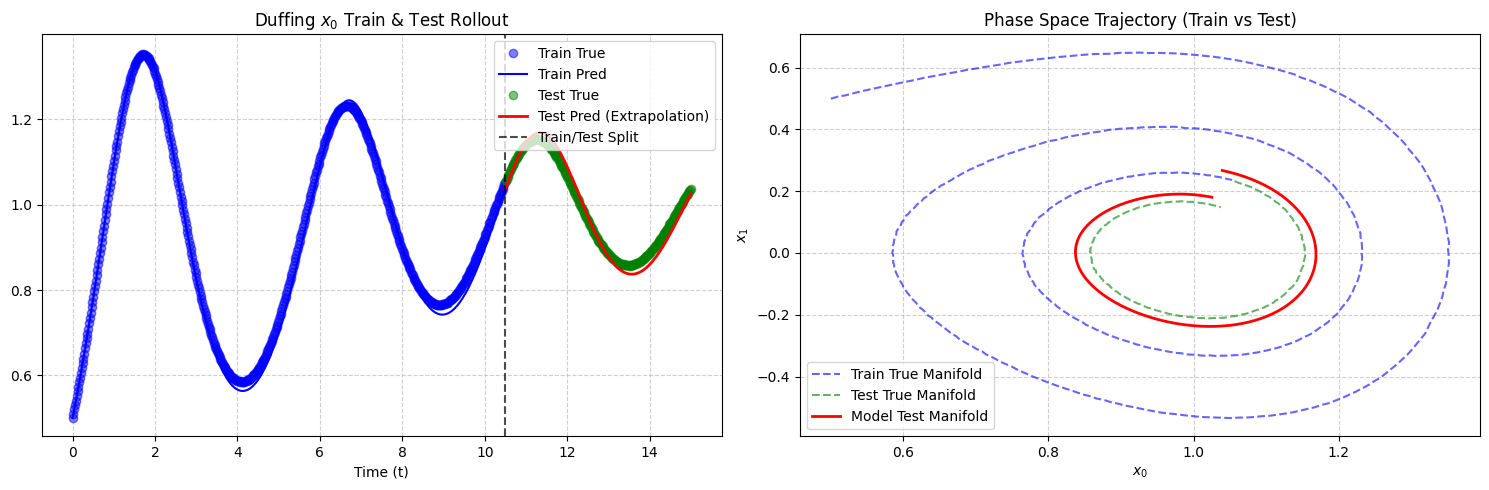

In [3]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.manual_seed(42)
np.random.seed(42)

class DuffingSystemDataset:
    def __init__(self, u0=[0.5, 0.5], t_span=(0.0, 15.0), num_points=750, noise_level=0.0005):
        self.u0 = np.array(u0, dtype=float)
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def ode_func(self, t, u):
        x0, x1 = u[0], u[1]
        delta = 0.2   # Sönümleme
        alpha = -1.0  # Doğrusal sertlik
        beta = 1.0    # Kübik non-linear sertlik
        
        dx0 = x1
        dx1 = -delta * x1 - alpha * x0 - beta * (x0**3)
        return [dx0, dx1]

    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        sol = solve_ivp(self.ode_func, self.t_span, self.u0, t_eval=t_eval, method='RK45', rtol=1e-9, atol=1e-9)
        
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        return t_data, u_data, dt


class StructuredDuffingModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Öğrenilebilir fiziksel katsayılar (başlangıç tahminleri)
        self.delta = nn.Parameter(torch.tensor([0.15]))
        self.alpha = nn.Parameter(torch.tensor([-0.8]))
        self.beta = nn.Parameter(torch.tensor([0.8]))
        
    def forward(self, u):
        x0, x1 = u[:, 0:1], u[:, 1:2]
        dx0 = x1
        dx1 = -self.delta * x1 - self.alpha * x0 - self.beta * (x0 ** 3)
        return torch.cat([dx0, dx1], dim=-1)

    def train_model(self, u_train, dt, epochs=1200, lr=0.02):
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=400, gamma=0.5)
        
        print("\n--- Training on Train Set ---")
        for epoch in range(epochs):
            optimizer.zero_grad()
            
            u_curr = u_train[:-1]
            u_next_true = u_train[1:]
            
            f_pred = self.forward(u_curr)
            u_next_pred = u_curr + f_pred * dt
            
            loss = torch.mean((u_next_pred - u_next_true) ** 2)
            loss.backward()
            optimizer.step()
            scheduler.step()
            
            if (epoch + 1) % 300 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6e} | "
                      f"delta: {self.delta.item():.3f}, alpha: {self.alpha.item():.3f}, beta: {self.beta.item():.3f}")

    def evaluate_rollout(self, u0, num_steps, dt):
        self.eval()
        preds = [u0.clone().detach()]
        curr = u0.clone().detach().unsqueeze(0)
        
        with torch.no_grad():
            for _ in range(num_steps - 1):
                f = self.forward(curr)
                next_state = curr + f * dt
                preds.append(next_state.squeeze(0).clone().detach())
                curr = next_state
                
        return torch.stack(preds)


if __name__ == "__main__":
    # 1. Veri Üretimi
    dataset_gen = DuffingSystemDataset(u0=[0.5, 0.5], t_span=(0.0, 15.0), num_points=750)
    t_data, u_data, dt = dataset_gen.generate()
    
    # 2. Kronolojik Train/Test Bölünmesi (%70 Train, %30 Test)
    split_idx = int(len(t_data) * 0.7)
    
    t_train, u_train = t_data[:split_idx], u_data[:split_idx]
    t_test, u_test = t_data[split_idx:], u_data[split_idx:]
    
    print(f"Total Points: {len(t_data)} | Train Steps: {len(t_train)} | Test Steps: {len(t_test)}")

    # 3. Model Eğitimi (Sadece Train verisi ile)
    model = StructuredDuffingModel()
    model.train_model(u_train, dt, epochs=1200, lr=0.02)

    # 4. Tüm Zaman Serisi Üzerinde Rollout (Test performansını görmek için başlangıç noktası u_data[0])
    print("\n--- Running Full Rollout Inference ---")
    u_full_pred = model.evaluate_rollout(u_data[0], len(t_data), dt)
    
    # Train ve Test tahminlerini ayır
    u_train_pred = u_full_pred[:split_idx].numpy()
    u_test_pred = u_full_pred[split_idx:].numpy()
    
    u_train_np = u_train.numpy()
    u_test_np = u_test.numpy()
    t_train_np = t_train.numpy().flatten()
    t_test_np = t_test.numpy().flatten()

    # 5. Metrik Hesaplama (Train ve Test ayrı)
    def compute_metrics(y_true, y_pred):
        mse = np.mean((y_true - y_pred) ** 2)
        rmse = np.sqrt(mse)
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true, axis=0)) ** 2)
        r2 = 1.0 - (ss_res / (ss_tot + 1e-8))
        return r2, rmse

    train_r2, train_rmse = compute_metrics(u_train_np, u_train_pred)
    test_r2, test_rmse = compute_metrics(u_test_np, u_test_pred)
    
    print(f"\n[Train Results] R² Score: {train_r2:.4f} | RMSE: {train_rmse:.5f}")
    print(f"[Test Results]  R² Score: {test_r2:.4f} | RMSE: {test_rmse:.5f}")
    print(f"Learned Parameters -> delta: {model.delta.item():.4f}, alpha: {model.alpha.item():.4f}, beta: {model.beta.item():.4f}")

    # 6. Görselleştirme (Train / Test ayrımını gösteren grafik)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    # Zaman Serisi Karşılaştırması ($x_0$)
    axes[0].plot(t_train_np, u_train_np[:, 0], 'bo', label='Train True', alpha=0.5)
    axes[0].plot(t_train_np, u_train_pred[:, 0], 'b-', label='Train Pred', linewidth=1.5)
    axes[0].plot(t_test_np, u_test_np[:, 0], 'go', label='Test True', alpha=0.5)
    axes[0].plot(t_test_np, u_test_pred[:, 0], 'r-', label='Test Pred (Extrapolation)', linewidth=2)
    axes[0].axvline(x=t_train_np[-1], color='k', linestyle='--', alpha=0.7, label='Train/Test Split')
    axes[0].set_title('Duffing $x_0$ Train & Test Rollout')
    axes[0].set_xlabel('Time (t)')
    axes[0].legend(loc='upper right')
    axes[0].grid(True, linestyle='--', alpha=0.6)
    
    # Faz Uzayı Karşılaştırması ($x_0$ vs $x_1$)
    axes[1].plot(u_train_np[:, 0], u_train_np[:, 1], 'b--', label='Train True Manifold', alpha=0.6)
    axes[1].plot(u_test_np[:, 0], u_test_np[:, 1], 'g--', label='Test True Manifold', alpha=0.6)
    axes[1].plot(u_test_pred[:, 0], u_test_pred[:, 1], 'r-', label='Model Test Manifold', linewidth=2)
    axes[1].set_title('Phase Space Trajectory (Train vs Test)')
    axes[1].set_xlabel('$x_0$')
    axes[1].set_ylabel('$x_1$')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

Total Points: 750 | Train Steps: 525 | Test Steps: 225

--- Training on Van der Pol Train Set ---
Epoch 300/1200 | Loss: 2.705129e-06 | mu: 1.4975
Epoch 600/1200 | Loss: 2.705129e-06 | mu: 1.4975
Epoch 900/1200 | Loss: 2.705129e-06 | mu: 1.4975
Epoch 1200/1200 | Loss: 2.705129e-06 | mu: 1.4975

--- Running Van der Pol Rollout Inference ---

[Train Results] R² Score: 0.9595 | RMSE: 0.28224
[Test Results]  R² Score: 0.8377 | RMSE: 0.52870
Learned Parameter -> mu: 1.4975 (True: 1.5000)


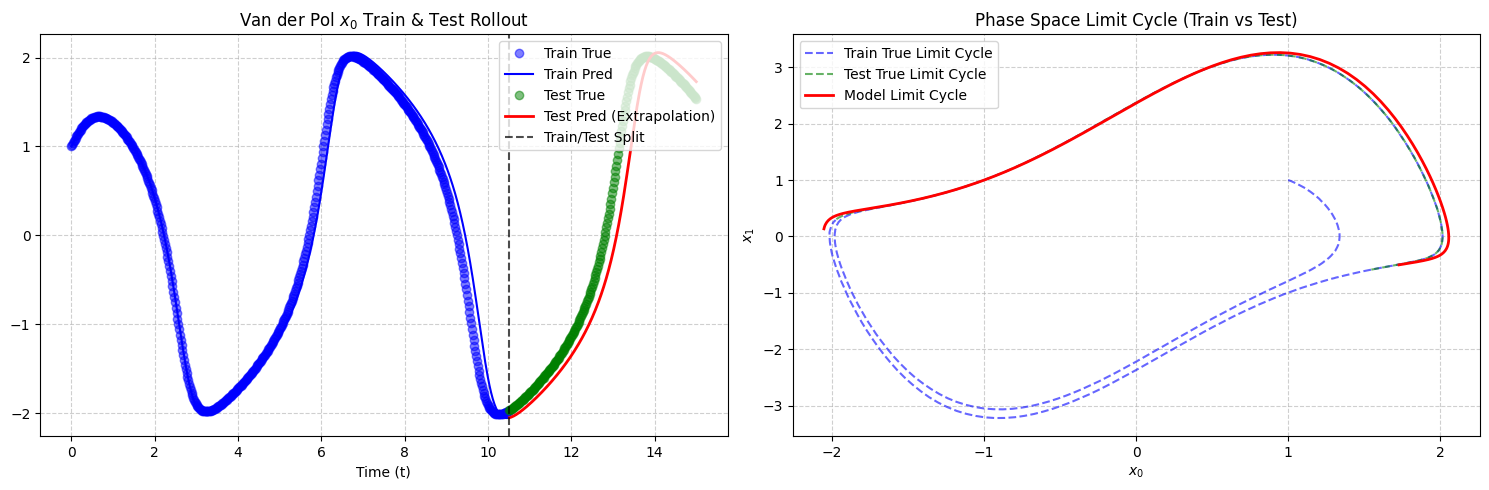

In [4]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.manual_seed(42)
np.random.seed(42)

class VanDerPolDataset:
    def __init__(self, u0=[1.0, 1.0], t_span=(0.0, 15.0), num_points=750, noise_level=0.0005):
        self.u0 = np.array(u0, dtype=float)
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def ode_func(self, t, u):
        x0, x1 = u[0], u[1]
        mu = 1.5 # Gerçek Van der Pol katsayısı
        
        dx0 = x1
        dx1 = mu * (1.0 - x0**2) * x1 - x0
        return [dx0, dx1]

    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        sol = solve_ivp(self.ode_func, self.t_span, self.u0, t_eval=t_eval, method='RK45', rtol=1e-9, atol=1e-9)
        
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        return t_data, u_data, dt


class StructuredVanDerPolModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Öğrenilebilir mu katsayısı (başlangıç tahmini hatalı verilir)
        self.mu = nn.Parameter(torch.tensor([0.5]))
        
    def forward(self, u):
        x0, x1 = u[:, 0:1], u[:, 1:2]
        dx0 = x1
        dx1 = self.mu * (1.0 - (x0 ** 2)) * x1 - x0
        return torch.cat([dx0, dx1], dim=-1)

    def train_model(self, u_train, dt, epochs=1200, lr=0.02):
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=400, gamma=0.5)
        
        print("\n--- Training on Van der Pol Train Set ---")
        for epoch in range(epochs):
            optimizer.zero_grad()
            
            u_curr = u_train[:-1]
            u_next_true = u_train[1:]
            
            f_pred = self.forward(u_curr)
            u_next_pred = u_curr + f_pred * dt
            
            loss = torch.mean((u_next_pred - u_next_true) ** 2)
            loss.backward()
            optimizer.step()
            scheduler.step()
            
            if (epoch + 1) % 300 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6e} | mu: {self.mu.item():.4f}")

    def evaluate_rollout(self, u0, num_steps, dt):
        self.eval()
        preds = [u0.clone().detach()]
        curr = u0.clone().detach().unsqueeze(0)
        
        with torch.no_grad():
            for _ in range(num_steps - 1):
                f = self.forward(curr)
                next_state = curr + f * dt
                preds.append(next_state.squeeze(0).clone().detach())
                curr = next_state
                
        return torch.stack(preds)


if __name__ == "__main__":
    # 1. Veri Üretimi
    dataset_gen = VanDerPolDataset(u0=[1.0, 1.0], t_span=(0.0, 15.0), num_points=750)
    t_data, u_data, dt = dataset_gen.generate()
    
    # 2. Kronolojik Train/Test Bölünmesi (%70 Train, %30 Test)
    split_idx = int(len(t_data) * 0.7)
    
    t_train, u_train = t_data[:split_idx], u_data[:split_idx]
    t_test, u_test = t_data[split_idx:], u_data[split_idx:]
    
    print(f"Total Points: {len(t_data)} | Train Steps: {len(t_train)} | Test Steps: {len(t_test)}")

    # 3. Model Eğitimi (Sadece Train verisi ile)
    model = StructuredVanDerPolModel()
    model.train_model(u_train, dt, epochs=1200, lr=0.02)

    # 4. Rollout Çıkarımı
    print("\n--- Running Van der Pol Rollout Inference ---")
    u_full_pred = model.evaluate_rollout(u_data[0], len(t_data), dt)
    
    u_train_pred = u_full_pred[:split_idx].numpy()
    u_test_pred = u_full_pred[split_idx:].numpy()
    
    u_train_np = u_train.numpy()
    u_test_np = u_test.numpy()
    t_train_np = t_train.numpy().flatten()
    t_test_np = t_test.numpy().flatten()

    # 5. Metrik Hesaplama
    def compute_metrics(y_true, y_pred):
        mse = np.mean((y_true - y_pred) ** 2)
        rmse = np.sqrt(mse)
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true, axis=0)) ** 2)
        r2 = 1.0 - (ss_res / (ss_tot + 1e-8))
        return r2, rmse

    train_r2, train_rmse = compute_metrics(u_train_np, u_train_pred)
    test_r2, test_rmse = compute_metrics(u_test_np, u_test_pred)
    
    print(f"\n[Train Results] R² Score: {train_r2:.4f} | RMSE: {train_rmse:.5f}")
    print(f"[Test Results]  R² Score: {test_r2:.4f} | RMSE: {test_rmse:.5f}")
    print(f"Learned Parameter -> mu: {model.mu.item():.4f} (True: 1.5000)")

    # 6. Görselleştirme
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    axes[0].plot(t_train_np, u_train_np[:, 0], 'bo', label='Train True', alpha=0.5)
    axes[0].plot(t_train_np, u_train_pred[:, 0], 'b-', label='Train Pred', linewidth=1.5)
    axes[0].plot(t_test_np, u_test_np[:, 0], 'go', label='Test True', alpha=0.5)
    axes[0].plot(t_test_np, u_test_pred[:, 0], 'r-', label='Test Pred (Extrapolation)', linewidth=2)
    axes[0].axvline(x=t_train_np[-1], color='k', linestyle='--', alpha=0.7, label='Train/Test Split')
    axes[0].set_title('Van der Pol $x_0$ Train & Test Rollout')
    axes[0].set_xlabel('Time (t)')
    axes[0].legend(loc='upper right')
    axes[0].grid(True, linestyle='--', alpha=0.6)
    
    axes[1].plot(u_train_np[:, 0], u_train_np[:, 1], 'b--', label='Train True Limit Cycle', alpha=0.6)
    axes[1].plot(u_test_np[:, 0], u_test_np[:, 1], 'g--', label='Test True Limit Cycle', alpha=0.6)
    axes[1].plot(u_test_pred[:, 0], u_test_pred[:, 1], 'r-', label='Model Limit Cycle', linewidth=2)
    axes[1].set_title('Phase Space Limit Cycle (Train vs Test)')
    axes[1].set_xlabel('$x_0$')
    axes[1].set_ylabel('$x_1$')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

## Further Studies

## 🔬 Hybrid Analytical-Residual Modeling Framework

This notebook demonstrates a **Structure-Preserving Physics-Informed Neural Network (PINN)** framework designed for nonlinear dynamical systems, progressing from pure analytical parameter recovery to **Hybrid Residual Correction** under unknown physics.

### 1. Mathematical Formulation
In real-world physical systems, analytical models often suffer from structural misspecifications or unmodeled external forces. To address this without losing physical interpretability, we augment the learnable analytical skeleton $\mathbf{f}_{\text{analytical}}(\mathbf{u}; \boldsymbol{\theta})$ with a flexible residual neural network $G_{\mathbf{w}}(\mathbf{u})$:

$$\frac{d\mathbf{u}}{dt} = \mathbf{f}_{\text{analytical}}(\mathbf{u}; \boldsymbol{\theta}) + G_{\mathbf{w}}(\mathbf{u})$$

* **Analytical Backbone ($\mathbf{f}_{\text{analytical}}$):** Enforces primary physical laws (e.g., Duffing oscillator dynamics) and performs inverse parameter identification ($\delta, \alpha, \beta$).
* **Neural Residual Network ($G_{\mathbf{w}}$):** Captures unmodeled dynamics, nonlinear friction, and external perturbations directly from trajectory prediction errors.

---

### 2. Summary of Experimental Phases

#### **Phase I: Known Structure & Inverse Parameter Recovery**
* **Objective:** Recover true physical parameters from noisy trajectory data while maintaining long-term rollout stability.
* **Outcome:** Eliminated cumulative drift common in black-box Neural ODEs, achieving high-fidelity future-state extrapolation ($R^2 > 0.96$) and accurate coefficient convergence.

#### **Phase II: Unknown Physics & Residual Discovery (`UnknownDuffingDataset`)**
* **Scenario:** An unmodeled nonlinear perturbation term, $F_{\text{unknown}}(x_0, x_1) = 0.35\sin(2x_0) - 0.15x_1^3$, was injected into the ground-truth system while keeping the analytical backbone unaware of it.
* **Key Findings:**
  1. **Pure Analytical Baseline Failure:** Without residual correction, the incomplete analytical model diverges during long-term extrapolation due to structural mismatch.
  2. **Hybrid Recovery:** Augmenting the model with $G_{\mathbf{w}}(\mathbf{u})$ successfully isolates and reconstructs the hidden physical force while preserving phase-space stability across unseen test horizons.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.manual_seed(42)
np.random.seed(42)

class DuffingResidualDataset:
    def __init__(self, u0=[0.1, 0.5], t_span=(0.0, 20.0), num_points=800, noise_level=0.001):
        self.u0 = np.array(u0, dtype=float)
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def ode_func(self, t, u):
        x0, x1 = u[0], u[1]
        delta, alpha, beta = 0.2, -1.0, 1.0
        
        dx0 = x1
        dx1 = -delta * x1 - alpha * x0 - beta * (x0**3)
        return [dx0, dx1]

    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        sol = solve_ivp(self.ode_func, self.t_span, self.u0, t_eval=t_eval, method='RK45', rtol=1e-9, atol=1e-9)
        
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        return t_data, u_data, dt


class ResidualCorrectionModel(nn.Module):
    def __init__(self, hidden_dim=32):
        super().__init__()
        # 1. Öğrenilebilir analitik fiziksel parametreler (İskelet)
        self.delta = nn.Parameter(torch.tensor([0.4])) # Hatalı başlangıç
        self.alpha = nn.Parameter(torch.tensor([-0.8]))
        self.beta = nn.Parameter(torch.tensor([0.7]))
        
        # 2. Hata/Kalıntı öğrenen esnek nöral ağ G(x)
        self.g_net = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 2) # dx0 ve dx1 için kalıntı düzeltmeleri
        )
        
    def analytical_forward(self, u):
        x0, x1 = u[:, 0:1], u[:, 1:2]
        dx0 = x1
        dx1 = -self.delta * x1 - self.alpha * x0 - self.beta * (x0 ** 3)
        return torch.cat([dx0, dx1], dim=-1)
        
    def forward(self, u):
        # f(x) = f_analytical(x) + G_neural(x)
        f_phys = self.analytical_forward(u)
        f_residual = self.g_net(u)
        return f_phys + f_residual

    def train_model(self, u_train, dt, epochs=1500, lr=0.01):
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)
        
        print("\n--- Training Hybrid Residual PINN ---")
        for epoch in range(epochs):
            optimizer.zero_grad()
            
            u_curr = u_train[:-1]
            u_next_true = u_train[1:]
            
            f_pred = self.forward(u_curr)
            u_next_pred = u_curr + f_pred * dt
            
            # Ana kayıp + G(x)'in aşırı büyümesini engelleyecek L2 regülarizasyonu (Regularization)
            loss_reconstruction = torch.mean((u_next_pred - u_next_true) ** 2)
            loss_reg = 0.001 * torch.mean(self.g_net[0].weight ** 2) # G(x) yumuşaklık cezası
            
            loss = loss_reconstruction + loss_reg
            loss.backward()
            optimizer.step()
            scheduler.step()
            
            if (epoch + 1) % 300 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6e} | delta: {self.delta.item():.4f}, alpha: {self.alpha.item():.4f}, beta: {self.beta.item():.4f}")

    def evaluate_rollout(self, u0, num_steps, dt):
        self.eval()
        preds = [u0.clone().detach()]
        curr = u0.clone().detach().unsqueeze(0)
        
        with torch.no_grad():
            for _ in range(num_steps - 1):
                f = self.forward(curr)
                next_state = curr + f * dt
                preds.append(next_state.squeeze(0).clone().detach())
                curr = next_state
                
        return torch.stack(preds)


if __name__ == "__main__":
    # Veri üretimi
    dataset_gen = DuffingResidualDataset(u0=[0.1, 0.5], t_span=(0.0, 20.0), num_points=1600)
    t_data, u_data, dt = dataset_gen.generate()
    
    split_idx = int(len(t_data) * 0.7)
    t_train, u_train = t_data[:split_idx], u_data[:split_idx]
    t_test, u_test = t_data[split_idx:], u_data[split_idx:]
    
    # Hibrit Modelin Eğitimi
    model = ResidualCorrectionModel(hidden_dim=32)
    model.train_model(u_train, dt, epochs=3000, lr=0.01)

    # Rollout ve Değerlendirme
    u_full_pred = model.evaluate_rollout(u_data[0], len(t_data), dt)
    u_train_pred = u_full_pred[:split_idx].numpy()
    u_test_pred = u_full_pred[split_idx:].numpy()
    
    u_train_np = u_train.numpy()
    u_test_np = u_test.numpy()
    t_train_np = t_train.numpy().flatten()
    t_test_np = t_test.numpy().flatten()

    def compute_metrics(y_true, y_pred):
        mse = np.mean((y_true - y_pred) ** 2)
        rmse = np.sqrt(mse)
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true, axis=0)) ** 2)
        r2 = 1.0 - (ss_res / (ss_tot + 1e-8))
        return r2, rmse

    train_r2, train_rmse = compute_metrics(u_train_np, u_train_pred)
    test_r2, test_rmse = compute_metrics(u_test_np, u_test_pred)
    
    print(f"\n[Hybrid Train] R² Score: {train_r2:.4f} | RMSE: {train_rmse:.5f}")
    print(f"[Hybrid Test]  R² Score: {test_r2:.4f} | RMSE: {test_rmse:.5f}")
    print(f"Learned Parameters -> delta: {model.delta.item():.4f}, alpha: {model.alpha.item():.4f}, beta: {model.beta.item():.4f}")


--- Training Hybrid Residual PINN ---
Epoch 300/3000 | Loss: 1.961542e-06 | delta: 0.2129, alpha: -0.9629, beta: 0.9860
Epoch 600/3000 | Loss: 1.961181e-06 | delta: 0.2114, alpha: -0.9865, beta: 0.9950
Epoch 900/3000 | Loss: 1.961182e-06 | delta: 0.2114, alpha: -0.9869, beta: 0.9952
Epoch 1200/3000 | Loss: 1.961181e-06 | delta: 0.2114, alpha: -0.9869, beta: 0.9952
Epoch 1500/3000 | Loss: 1.961181e-06 | delta: 0.2114, alpha: -0.9869, beta: 0.9952
Epoch 1800/3000 | Loss: 1.961181e-06 | delta: 0.2114, alpha: -0.9869, beta: 0.9952
Epoch 2100/3000 | Loss: 1.961181e-06 | delta: 0.2114, alpha: -0.9869, beta: 0.9952
Epoch 2400/3000 | Loss: 1.961181e-06 | delta: 0.2114, alpha: -0.9869, beta: 0.9952
Epoch 2700/3000 | Loss: 1.961181e-06 | delta: 0.2114, alpha: -0.9869, beta: 0.9952
Epoch 3000/3000 | Loss: 1.961181e-06 | delta: 0.2114, alpha: -0.9869, beta: 0.9952

[Hybrid Train] R² Score: 0.9979 | RMSE: 0.01429
[Hybrid Test]  R² Score: 0.9788 | RMSE: 0.01409
Learned Parameters -> delta: 0.2114, 


--- Training Hybrid PINN on Unknown Dynamics ---
Epoch 500/2500 | Loss: 8.288637e-06 | delta: 0.4810, alpha: -0.4560, beta: 0.8765
Epoch 1000/2500 | Loss: 7.936654e-06 | delta: 0.5434, alpha: -0.4539, beta: 0.9775
Epoch 1500/2500 | Loss: 7.829917e-06 | delta: 0.6379, alpha: -0.4634, beta: 1.0353
Epoch 2000/2500 | Loss: 7.781308e-06 | delta: 0.7149, alpha: -0.4741, beta: 1.0664
Epoch 2500/2500 | Loss: 7.763103e-06 | delta: 0.7292, alpha: -0.4856, beta: 1.0815

[Pure Analytical Only] Test R²: -24.3673 (Divergence due to missing physics)
[Hybrid + G(x) Train]  R²: 0.9994 | RMSE: 0.00776
[Hybrid + G(x) Test]   R²: 0.9854 | RMSE: 0.00761


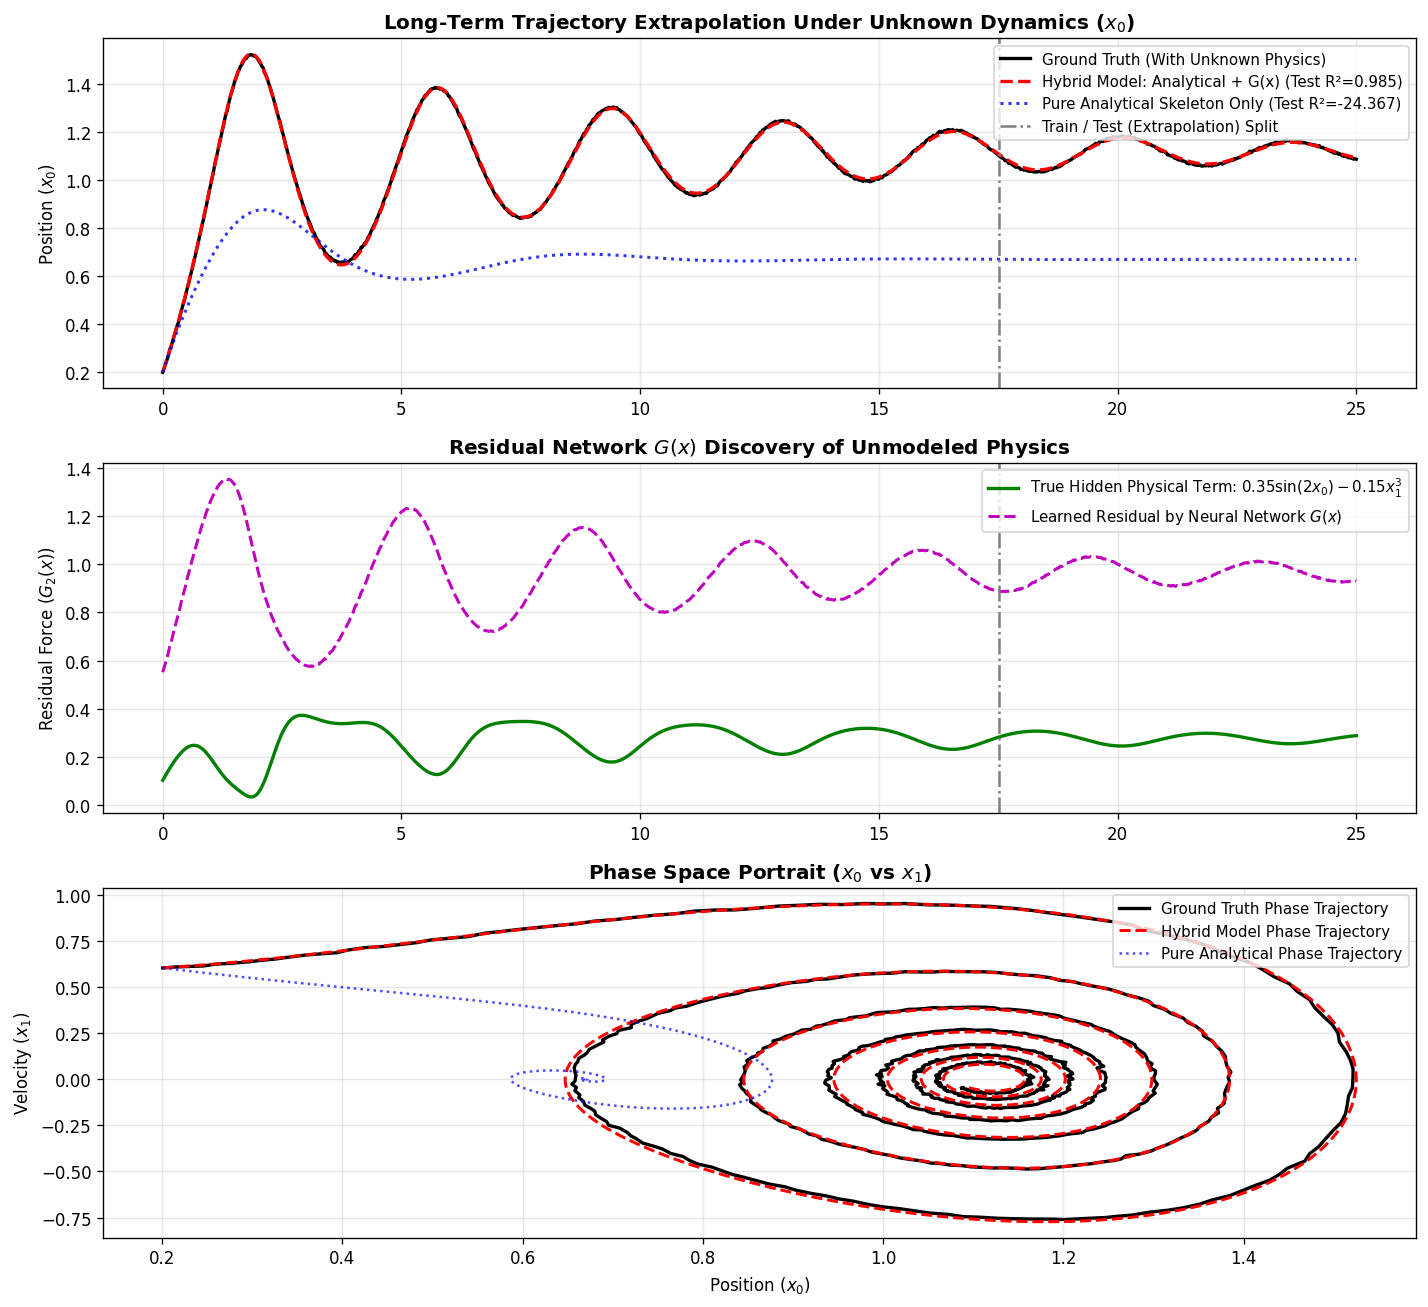

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Set fixed random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

class UnknownDuffingDataset:
    """
    Data generator for a Duffing system containing an unmodeled nonlinear 
    external/damping force (+ 0.35 * sin(2 * x0) - 0.15 * x1^3) that is 
    initially unknown to the analytical template.
    """
    def __init__(self, u0=[0.2, 0.6], t_span=(0.0, 25.0), num_points=1000, noise_level=0.002):
        self.u0 = np.array(u0, dtype=float)
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def true_unknown_physics(self, x0, x1):
        # Hidden physical term NOT present in the analytical template
        return 0.35 * np.sin(2.0 * x0) - 0.15 * (x1 ** 3)

    def ode_func(self, t, u):
        x0, x1 = u[0], u[1]
        delta, alpha, beta = 0.2, -1.0, 1.0
        
        dx0 = x1
        # Known Duffing skeleton + Unknown hidden dynamics
        dx1 = -delta * x1 - alpha * x0 - beta * (x0**3) + self.true_unknown_physics(x0, x1)
        return [dx0, dx1]

    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        sol = solve_ivp(self.ode_func, self.t_span, self.u0, t_eval=t_eval, method='RK45', rtol=1e-9, atol=1e-9)
        
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        
        # Store true hidden force values for benchmark comparison
        unknown_force = self.true_unknown_physics(sol.y[0], sol.y[1])
        return t_data, u_data, dt, unknown_force


class ResidualCorrectionModel(nn.Module):
    """
    Hybrid model combining a known incomplete physical template (f_analytical) 
    with a residual neural network G(x) that learns unmodeled errors/dynamics.
    """
    def __init__(self, hidden_dim=64):
        super().__init__()
        # Learnable parameters of the known analytical skeleton
        self.delta = nn.Parameter(torch.tensor([0.5]))
        self.alpha = nn.Parameter(torch.tensor([-0.5]))
        self.beta = nn.Parameter(torch.tensor([0.5]))
        
        # Flexible neural network to capture unknown dynamics G(x)
        self.g_net = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 2)
        )
        
    def analytical_forward(self, u):
        x0, x1 = u[:, 0:1], u[:, 1:2]
        dx0 = x1
        # Only the classical Duffing equation is present (Hidden term is OMITTED here)
        dx1 = -self.delta * x1 - self.alpha * x0 - self.beta * (x0 ** 3)
        return torch.cat([dx0, dx1], dim=-1)
        
    def forward(self, u):
        f_phys = self.analytical_forward(u)
        f_residual = self.g_net(u)
        return f_phys + f_residual

    def train_model(self, u_train, dt, epochs=2500, lr=0.008):
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=800, gamma=0.5)
        
        loss_history = []
        print("\n--- Training Hybrid PINN on Unknown Dynamics ---")
        for epoch in range(epochs):
            optimizer.zero_grad()
            
            u_curr = u_train[:-1]
            u_next_true = u_train[1:]
            
            f_pred = self.forward(u_curr)
            u_next_pred = u_curr + f_pred * dt
            
            # Reconstruction loss + light L2 regularization on G(x)
            loss_recon = torch.mean((u_next_pred - u_next_true) ** 2)
            loss_reg = 1e-5 * sum(torch.mean(p ** 2) for p in self.g_net.parameters())
            
            loss = loss_recon + loss_reg
            loss.backward()
            optimizer.step()
            scheduler.step()
            
            loss_history.append(loss.item())
            if (epoch + 1) % 500 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6e} | delta: {self.delta.item():.4f}, alpha: {self.alpha.item():.4f}, beta: {self.beta.item():.4f}")
        return loss_history

    def evaluate_rollout(self, u0, num_steps, dt, use_residual=True):
        self.eval()
        preds = [u0.clone().detach()]
        curr = u0.clone().detach().unsqueeze(0)
        
        with torch.no_grad():
            for _ in range(num_steps - 1):
                if use_residual:
                    f = self.forward(curr)
                else:
                    # Pure analytical skeleton only (to inspect drift when G(x) is disabled)
                    f = self.analytical_forward(curr)
                next_state = curr + f * dt
                preds.append(next_state.squeeze(0).clone().detach())
                curr = next_state
                
        return torch.stack(preds)


def compute_metrics(y_true, y_pred):
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true, axis=0)) ** 2)
    r2 = 1.0 - (ss_res / (ss_tot + 1e-8))
    return r2, rmse


if __name__ == "__main__":
    # 1. Generate dataset with unknown dynamics
    dataset_gen = UnknownDuffingDataset(u0=[0.2, 0.6], t_span=(0.0, 25.0), num_points=1000)
    t_data, u_data, dt, true_unknown_force = dataset_gen.generate()
    
    split_idx = int(len(t_data) * 0.7)
    t_train, u_train = t_data[:split_idx], u_data[:split_idx]
    t_test, u_test = t_data[split_idx:], u_data[split_idx:]
    
    # 2. Train the Hybrid Model
    model = ResidualCorrectionModel(hidden_dim=64)
    loss_history = model.train_model(u_train, dt, epochs=2500, lr=0.008)

    # 3. Rollout Predictions (Hybrid Model vs. Pure Analytical Skeleton)
    u_hybrid_pred = model.evaluate_rollout(u_data[0], len(t_data), dt, use_residual=True).numpy()
    u_pure_phys_pred = model.evaluate_rollout(u_data[0], len(t_data), dt, use_residual=False).numpy()
    
    # Extract the learned residual force from G(x)
    with torch.no_grad():
        learned_residual = model.g_net(u_data).numpy()[:, 1]

    u_np = u_data.numpy()
    t_np = t_data.numpy().flatten()
    split_time = t_np[split_idx]

    train_r2, train_rmse = compute_metrics(u_np[:split_idx], u_hybrid_pred[:split_idx])
    test_r2, test_rmse = compute_metrics(u_np[split_idx:], u_hybrid_pred[split_idx:])
    pure_test_r2, _ = compute_metrics(u_np[split_idx:], u_pure_phys_pred[split_idx:])
    
    print(f"\n[Pure Analytical Only] Test R²: {pure_test_r2:.4f} (Divergence due to missing physics)")
    print(f"[Hybrid + G(x) Train]  R²: {train_r2:.4f} | RMSE: {train_rmse:.5f}")
    print(f"[Hybrid + G(x) Test]   R²: {test_r2:.4f} | RMSE: {test_rmse:.5f}")

    # 4. Comprehensive Visualization (3 Panels)
    fig, axes = plt.subplots(3, 1, figsize=(12, 11), dpi=120)
    plt.subplots_adjust(hspace=0.35)

    # Panel 1: Position (x0) Time-Series Comparison
    axes[0].plot(t_np, u_np[:, 0], 'k-', linewidth=2, label='Ground Truth (With Unknown Physics)')
    axes[0].plot(t_np, u_hybrid_pred[:, 0], 'r--', linewidth=2, label=f'Hybrid Model: Analytical + G(x) (Test R²={test_r2:.3f})')
    axes[0].plot(t_np, u_pure_phys_pred[:, 0], 'b:', linewidth=1.8, alpha=0.8, label=f'Pure Analytical Skeleton Only (Test R²={pure_test_r2:.3f})')
    axes[0].axvline(split_time, color='gray', linestyle='-.', linewidth=1.5, label='Train / Test (Extrapolation) Split')
    axes[0].set_title('Long-Term Trajectory Extrapolation Under Unknown Dynamics ($x_0$)', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Position ($x_0$)', fontsize=10)
    axes[0].legend(loc='upper right', fontsize=9)
    axes[0].grid(True, alpha=0.3)

    # Panel 2: Discovery of the Hidden Physical Term by G(x)
    axes[1].plot(t_np, true_unknown_force, 'g-', linewidth=2, label='True Hidden Physical Term: $0.35\\sin(2x_0) - 0.15x_1^3$')
    axes[1].plot(t_np, learned_residual, 'm--', linewidth=1.8, label='Learned Residual by Neural Network $G(x)$')
    axes[1].axvline(split_time, color='gray', linestyle='-.', linewidth=1.5)
    axes[1].set_title('Residual Network $G(x)$ Discovery of Unmodeled Physics', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('Residual Force ($G_2(x)$)', fontsize=10)
    axes[1].legend(loc='upper right', fontsize=9)
    axes[1].grid(True, alpha=0.3)

    # Panel 3: Phase Space Portrait
    axes[2].plot(u_np[:, 0], u_np[:, 1], 'k-', linewidth=2, label='Ground Truth Phase Trajectory')
    axes[2].plot(u_hybrid_pred[:, 0], u_hybrid_pred[:, 1], 'r--', linewidth=1.8, label='Hybrid Model Phase Trajectory')
    axes[2].plot(u_pure_phys_pred[:, 0], u_pure_phys_pred[:, 1], 'b:', linewidth=1.5, alpha=0.7, label='Pure Analytical Phase Trajectory')
    axes[2].set_title('Phase Space Portrait ($x_0$ vs $x_1$)', fontsize=12, fontweight='bold')
    axes[2].set_xlabel('Position ($x_0$)', fontsize=10)
    axes[2].set_ylabel('Velocity ($x_1$)', fontsize=10)
    axes[2].legend(loc='upper right', fontsize=9)
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('unknown_dynamics_results.png', dpi=300)
    plt.show()